In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

# 계층 클러스터링(hierarchial clustering)

계층 클러스터링 알고리즘은 데이터 간 계층을 기반으로 데이터 간 병합 또는 분할을 통해서 해당 데이터 포인트가 속할 그룹을 결정하는 알고리즘으로 크게 `병합 계층` 클러스터링(agglomerative hierarchial clustering)과 `분할 계층` 클러스터링(division hierarchial clustering)으로 나눌 수 있다.

병합 계층 클러스터링은 `개별 데이터` 포인트를 `하나의 클러스터로 설정`하고 시작하는 방법으로 데이터 포인트가 100개가 있다면 100개의 클러스터가 존재한다고 설정하는 것이다. 그리고 각 클러스터를 비교해서 클러스터간 `유사도가 높을 경우 두 개의 클러스터를 하나의 클러스터로 합치는 방법`이다. 처음에는 다수의 클러스터로 시작하지만 결국에는 데이터셋 전체가 하나의 클러스터로 묶이는 방법이다.

분할 계층 클러스터링은 병합 계층 클러스터링과는 반대로 `전체 데이터셋을 하나의 클러스터로 설정`하고 시작하는 방법으로 데이터 포인트가 100개가 있다면 이 데이터셋 전체를 1개의 클러스터도 설정하고 시작하는 것이다. 그리고 클러스터 내부에서 가장 멀리 떨어진 데이터 포인트를 다른 클러스터로 분리하는 방법이다. 처음에는 하나의 클러스터로 시작하지만 결국에는 클러스터가 `데이터 포인트 개수만큼 분리`되는 방법이다.

## 사이킷런에서 제공하는 데이터를 이용하는 병합 계층 클러스터링 알고리즘을 적용한다.

In [2]:
x_train, y_train = datasets.make_blobs(n_samples=100, n_features=2, centers=6, random_state=23)
print(x_train.shape, y_train.shape)

(100, 2) (100,)


## 병합 계층 클러스터링 적용 전 데이터 시각화

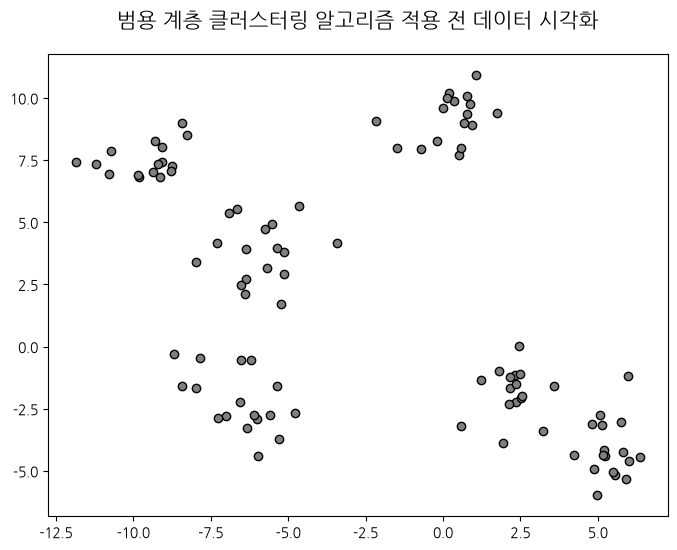

In [4]:
plt.figure(figsize=[8, 6])
plt.scatter(x_train[:, 0], x_train[:, 1], c='gray', edgecolors='black', marker='o')
plt.title('범용 계층 클러스터링 알고리즘 적용 전 데이터 시각화', pad=20, fontsize=15)
plt.show()

## 병합 계층 클러스터링 모델을 만들고 학습 시킨다. - 개별 데이터를 각각 한 개의 클러스터로 학습한다.

병합 계층 클러스터링 알고리즘을 사용하기 위해 AgglomerativeClustering를 import 한다.

In [5]:
from sklearn.cluster import AgglomerativeClustering

n_clusters에 군집화하려는 클러스터의 개수를 linkage에 거리를 측정하는 방법 지정해서 병합 계층 클러스터링 모델을 만들고 군집화할 데이터를 넘겨서 학습시킨다.

모든 데이터가 각각 하나의 클러스터를 구성하는 것을 보고 싶으면 n_clusters를 None으로 지정하면 되는데 distance_threshold를 0으로 지정해야 한다.  
linkage는 ward가 기본값이고 complete, anerage, single를 지정할 수 있다.  
ward: 병합되는 클러스터들의 분산을 최소로 한다. 최소 분산 기법  
complete: 모든 데이터 조합에 대한 거리를 측정해서 가장 큰 값을 구한다. 최장 거리 방법  
anerage: 모든 데이터 조합에 대한 거리를 측정해서 평균 값을 구한다. 평균 거리 방법  
single: 모든 데이터 조합에 대한 거리를 측정해서 가장 작은 값을 구한다. 최소 거리 방법  

In [9]:
model = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage='complete')
model.fit(x_train)

AgglomerativeClustering(distance_threshold=0, linkage='complete',
                        n_clusters=None)

## 클러스터링 결과를 확인한다.

labels_ 속성으로 클러스터링 결과를 확인할 수 있다.

In [10]:
print(model.labels_)

[76 71 59 65 62 79 94 95 73 85 69 86 89 64 93 92 74 88 87 81 56 99 43 84
 97 80 49 78 60 98 39 91 36 90 53 45 83 50 52 77 66 48 82 40 58 61 70 96
 72 55 42 57 35 67 24 47 19 23 34 68 28 75 46 51 32 38 17 54 37 22 26 44
 30 18 21 33 10 41 29 27  8 13 20 16 63 31  9 25 14 12 11  5  6  4  2 15
  7  3  1  0]


fit_predict() 메소드에 피처 데이터를 넘겨서 예측하면 클러스터링과 같은 결과가 나온다.

In [11]:
print(model.fit_predict(x_train))

[76 71 59 65 62 79 94 95 73 85 69 86 89 64 93 92 74 88 87 81 56 99 43 84
 97 80 49 78 60 98 39 91 36 90 53 45 83 50 52 77 66 48 82 40 58 61 70 96
 72 55 42 57 35 67 24 47 19 23 34 68 28 75 46 51 32 38 17 54 37 22 26 44
 30 18 21 33 10 41 29 27  8 13 20 16 63 31  9 25 14 12 11  5  6  4  2 15
  7  3  1  0]


## 병합 계층 클러스터링 모델을 만들고 학습 시킨다. - 개별 데이터를 n 개의 클러스터로 학습한다.

In [12]:
model = AgglomerativeClustering(n_clusters=6, linkage='complete')
model.fit(x_train)

AgglomerativeClustering(linkage='complete', n_clusters=6)

In [14]:
print(model.labels_)
print(model.fit_predict(x_train))

[2 5 2 1 3 0 0 3 1 3 3 2 3 4 1 4 2 5 5 4 5 1 2 0 0 3 0 0 3 5 5 2 3 1 5 3 2
 1 3 1 2 4 0 4 0 2 4 3 1 1 3 2 0 3 0 5 5 1 4 0 1 5 4 5 3 3 4 0 2 1 5 2 4 4
 5 0 5 3 0 1 1 0 2 2 5 5 4 4 4 0 0 2 4 3 2 1 1 4 2 1]
[2 5 2 1 3 0 0 3 1 3 3 2 3 4 1 4 2 5 5 4 5 1 2 0 0 3 0 0 3 5 5 2 3 1 5 3 2
 1 3 1 2 4 0 4 0 2 4 3 1 1 3 2 0 3 0 5 5 1 4 0 1 5 4 5 3 3 4 0 2 1 5 2 4 4
 5 0 5 3 0 1 1 0 2 2 5 5 4 4 4 0 0 2 4 3 2 1 1 4 2 1]


## 데이터프레임을 만들고 파생 변수를 만들고 각 데이터가 할당된 클러스터를 넣어준다.

In [15]:
df = pd.DataFrame(x_train, columns=['x', 'y'])
df['label_1'] = y_train # make_blobs() 메소드를 실행해서 얻은 클러스터의 중심
df['label_2'] = model.labels_ # 병합 계층 클러스터링 알고리즘으로 얻은 클러스터의 중심
df.head(20)

,x,y,label_1,label_2
0,0.884120,9.751371,0,2
1,1.944001,-3.858644,4,5
2,-0.001501,9.609392,0,2
3,5.928309,-5.344657,1,1
4,-6.402031,2.126333,2,3
5,-6.206620,-0.533699,3,0
6,-6.003600,-2.896963,3,0
7,-7.302346,4.185701,2,3
8,6.012819,-4.620225,1,1
9,-6.374456,2.712907,2,3


## 병합 계층 클러스터링 적용 후 데이터 시각화

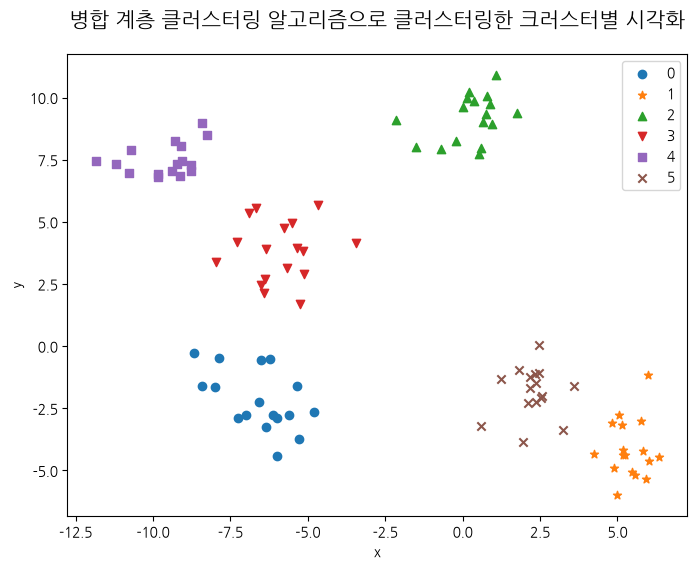

In [16]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for index, marker in enumerate(markers):
    df_index = df[df.label_2 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('병합 계층 클러스터링 알고리즘으로 클러스터링한 클러스터별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 모델을 평가한다.

In [17]:
score = silhouette_score(x_train, model.labels_)
print(score)

0.6580963691356235


## 덴드로그램(dendrogram) 시각화

계층적 클러스터링 결과를 트리 구조로 나타내는 그림을 덴드로그램이라 한다.

덴드로그램 시각화를 하기 위해서 dendrogram과 linkage를 import 한다.

In [19]:
from scipy.cluster.hierarchy import dendrogram, linkage

In [18]:
x_train, y_train = datasets.make_blobs(n_samples=20, n_features=2, centers=6, random_state=23)
print(x_train.shape, y_train.shape)
model = AgglomerativeClustering(n_clusters=None, linkage='complete', distance_threshold=0)
model.fit(x_train)
print(model.labels_)

(20, 2) (20,)
[10 19 11 18 13  9 12 15 17 16 14  5  7  6  8  3  4  1  2  0]


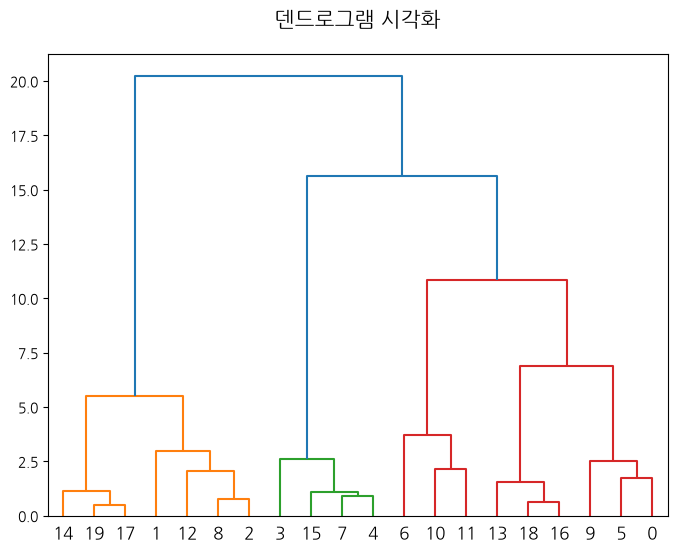

In [22]:
plt.figure(figsize=[8, 6])
link = linkage(x_train, 'complete')
dendrogram(link, orientation='top', labels=model.labels_)
plt.title('덴드로그램 시각화', pad=20, fontsize=15)
plt.show()